# 3.5 — Brightness criterion example

Brightness is the mean of Pillow's rounded RGB-to-L values:
`Y = 0.299 R + 0.587 G + 0.114 B`, on a fixed 0–255 scale.
Near-black and near-white fractions include their configured cutoff boundaries.
This is an intensity measurement, not physical luminance or subject readability.

**Interface:** dictionary settings → `BrightnessCriterion.analyze(AnalysisInput(image))` → result dictionary.

No brand scores or acceptance thresholds are applied. Synthetic examples require no downloads.

In [1]:
import json

import matplotlib.pyplot as plt
import numpy as np
from IPython.display import display
from PIL import Image


In [2]:
from brandlens.cv.cv_input import CVInput
from brandlens.cv.brightness_criterion import BrightnessCriterion

criterion = BrightnessCriterion()
print("Resolved settings:", criterion.settings)

Resolved settings: {'near_black_max': 10, 'near_white_min': 245}


## Synthetic examples

Compare the images with their grayscale histograms. These RGB images are interpreted
as sRGB and can be used directly. Real photographs need the existing standardizer.

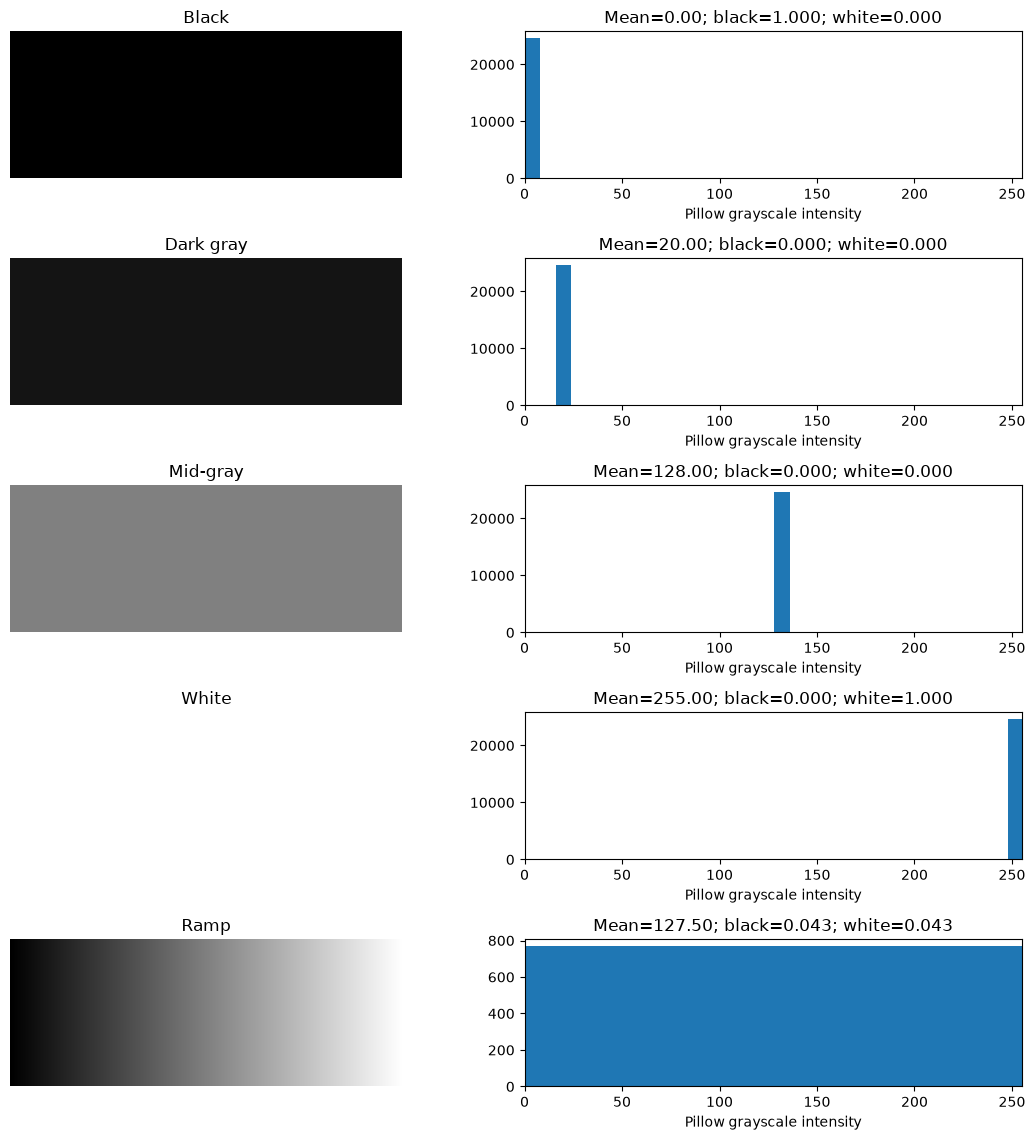

In [3]:
images = {
    "Black": Image.new("RGB", (256, 96), (0, 0, 0)),
    "Dark gray": Image.new("RGB", (256, 96), (20, 20, 20)),
    "Mid-gray": Image.new("RGB", (256, 96), (128, 128, 128)),
    "White": Image.new("RGB", (256, 96), (255, 255, 255)),
    "Ramp": Image.fromarray(np.tile(np.arange(256, dtype=np.uint8), (96, 1))).convert(
        "RGB"
    ),
}
results = {}
fig, axes = plt.subplots(len(images), 2, figsize=(11, 2.3 * len(images)))
for row, (name, image) in enumerate(images.items()):
    result = criterion.analyze(CVInput(image))
    results[name] = result
    axes[row, 0].imshow(image)
    axes[row, 0].set_title(name)
    axes[row, 0].axis("off")
    with image.convert("L") as gray:
        axes[row, 1].hist(np.asarray(gray).ravel(), bins=32, range=(0, 256))
    axes[row, 1].set_xlim(0, 255)
    axes[row, 1].set_xlabel("Pillow grayscale intensity")
    b = result["measurements"]
    axes[row, 1].set_title(
        f"Mean={b['mean_luminance']:.2f}; "
        f"black={b['near_black_fraction']:.3f}; white={b['near_white_fraction']:.3f}"
    )
fig.tight_layout()
plt.show()

## Inspect the result dictionary

`status="available"` means the measurement is computable, not that the image passes.
`method.parameters` records the resolved settings. `units` describes the measurement
scales. `reasons` explains unavailable measurements when a criterion supports that case.
This local result format is not yet an adapter for the project's HTTP API.

In [4]:
example_name = next(iter(results))
print(example_name)
print(json.dumps(results[example_name], indent=2, allow_nan=False))

Black
{
  "schema_version": "1.0.0",
  "criterion_id": "exposure_brightness",
  "status": "available",
  "measurements": {
    "mean_luminance": 0.0,
    "near_black_fraction": 1.0,
    "near_white_fraction": 0.0
  },
  "method": {
    "id": "pillow_grayscale_brightness",
    "version": "1",
    "parameters": {
      "near_black_max": 10,
      "near_white_min": 245
    }
  },
  "units": {
    "mean_luminance": "grayscale_0_255",
    "near_black_fraction": "fraction_0_1",
    "near_white_fraction": "fraction_0_1"
  },
  "reasons": []
}


## Check known numerical outcomes

These assertions demonstrate measurement definitions on controlled inputs.

In [5]:
assert results["Black"]["measurements"]["mean_luminance"] == 0.0
assert results["White"]["measurements"]["mean_luminance"] == 255.0
assert results["Ramp"]["measurements"]["mean_luminance"] == 127.5
assert results["Ramp"]["measurements"]["near_black_fraction"] == 11 / 256
assert results["Ramp"]["measurements"]["near_white_fraction"] == 11 / 256

# Pillow rounds pure R/G/B to 76, 150 and 29, respectively.
with Image.new("RGB", (3, 1)) as rgb:
    rgb.putdata([(255, 0, 0), (0, 255, 0), (0, 0, 255)])
    assert (
        criterion.analyze(CVInput(rgb))["measurements"]["mean_luminance"] == 85.0
    )
print("Known brightness outcomes verified.")

Known brightness outcomes verified.


## Dictionary settings and inclusive boundaries

A partial dictionary overrides only supplied defaults. These settings determine what
gets counted; they are not brand pass/fail limits. Create a new criterion to change settings.

In [6]:
custom = BrightnessCriterion({"near_black_max": 11, "near_white_min": 244})
partial = BrightnessCriterion({"near_black_max": 20})
print("Partial override:", partial.settings)
with Image.new("RGB", (6, 1)) as boundaries:
    boundaries.putdata([(v, v, v) for v in (0, 10, 11, 244, 245, 255)])
    data = CVInput(boundaries)
    default_result = criterion.analyze(data)["measurements"]
    custom_result = custom.analyze(data)["measurements"]
print("Default:", default_result)
print("Custom: ", custom_result)

# Some assertions to verify that the custom settings are applied correctly (for demo only, covered in unittests).
assert default_result["near_black_fraction"] == 1 / 3
assert custom_result["near_black_fraction"] == 0.5
assert custom_result["near_white_fraction"] == 0.5

# Accessing settings returns a copy, so this cannot alter the instance.
snapshot = custom.settings
snapshot["near_black_max"] = -1
assert custom.settings["near_black_max"] == 11

Partial override: {'near_black_max': 20, 'near_white_min': 245}
Default: {'mean_luminance': 127.5, 'near_black_fraction': 0.3333333333333333, 'near_white_fraction': 0.3333333333333333}
Custom:  {'mean_luminance': 127.5, 'near_black_fraction': 0.5, 'near_white_fraction': 0.5}


## Optional real photograph

Set a path below. This section uses your existing `standardize_image()` for EXIF
orientation, sRGB conversion and transparency handling. Merely calling `.convert("RGB")`
is not a replacement for color-profile standardization. Default standardization retains
resolution; measurement results can depend on preprocessing choices.

In [7]:
photo_path = None  # Example: repo_root / "data" / "example.jpg"
if photo_path is not None:
    from brandlens.preprocessing.standardization import standardize_image

    with Image.open(photo_path) as original:
        standardized = standardize_image(original)
    try:
        display(standardized)
        result = criterion.analyze(CVInput(standardized))
        print(json.dumps(result, indent=2, allow_nan=False))
    finally:
        standardized.close()
else:
    print("Optional real-photo section skipped; set photo_path to run it.")

Optional real-photo section skipped; set photo_path to run it.


## Next integration step

A caller can put multiple criterion objects in a list and call `analyze(data)` on each.
Each returns the same outer structure with different measurements. Brand evaluation
should consume these measurements separately. Changing an algorithm may require
recalibration even if its result keys remain the same.